# Profiling

Profiles a few steps of a model on a Modal GPU. A `Profile` declares one run: the model, the optimizer, the GPU, the kind of step and the switches. `run_profile` runs it now and keeps nothing; `profiling_experiment.ipynb` declares a series, kept on the volume. Either way you get a `Profile` whose methods hold the analysis.

In [ ]:
from IPython.display import SVG

from artifacts.core.artifact import Resources
from artifacts.core.SGD.optimizers import SGD
from artifacts.profiles import Profile
from models.transformer import Transformer
from profiling.attribution_diagrams import render
from profiling.profile_events import launch_chain
from profiling.util import run_profile

In [ ]:
spec = Profile(
    run_id="scratch",
    resources=Resources(gpu_type="T4"),
    model=Transformer(
        vocab_size=10000,
        sequence_length=512,
        dtype="torch.float32",
        num_layers=4,
        d_model=128,
        d_ff=256,
        num_heads=4,
        rope_theta=10000,
    ),
    optimizer=SGD(),
    step_kind="full",  # or "forward": the forward alone, without gradients
    batch_size=4,
    seed=0,
    warmup_steps=5,  # enough for a compiled step to finish compiling
    profile_steps=3,
    autocast=None,  # or "torch.bfloat16": what forward and loss run in; None runs in the model's dtype
    compile="default",  # a torch.compile mode ("default", "max-autotune"), or None to run eagerly
    kernel_events=True,
    module_scopes=False,  # must be False with compile
    peak_memory=True,
    trace_memory=True,
)

## One profile, kept nowhere

`run_profile` runs the profile on its GPU and returns it holding its files in memory.

In [ ]:
result = run_profile(spec)

In [4]:
# One row per step: the profile's parameters, what it measured, and the rates derived from it.
result.summary().T

,0,1,2
step,0,1,2
autocast,None,None,None
batch_size,4,4,4
compile,default,default,default
kernel_events,True,True,True
module_scopes,False,False,False
peak_memory,True,True,True
profile_steps,3,3,3
run_id,scratch,scratch,scratch
seed,0,0,0


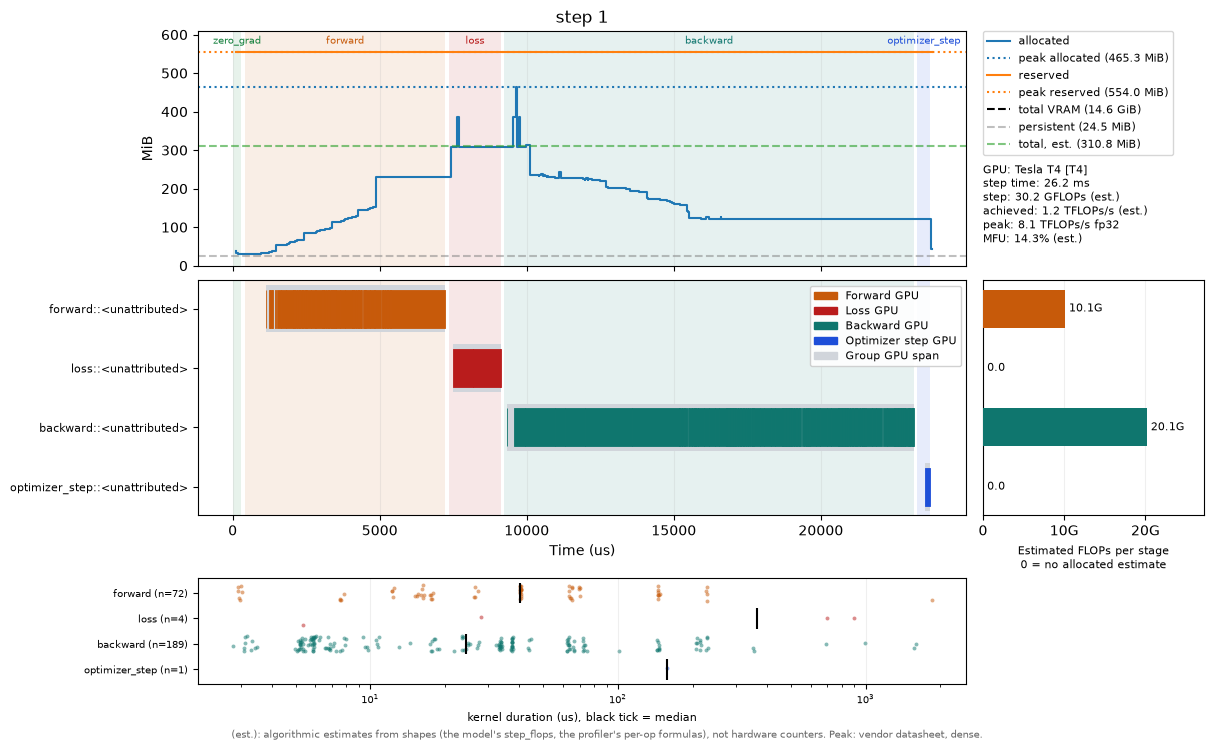

In [5]:
result.display_steps(steps=[1])

In [6]:
# Kernels grouped by phase and module, the module cut to depth FQN parts; by phase only when compiled.
groups, kernels, unattributed_kernels, flop_sources = result.aggregate_kernels(1, depth=1)
display(groups[["kernel_count", "gpu_time_us", "gpu_span_us", *groups.filter(like="est_flops").columns]])

,,kernel_count,gpu_time_us,gpu_span_us,total_est_flops,bmm_est_flops,mm_est_flops
phase,module_fqn,,,,,,
forward,<unattributed>,72,5784.787,6102.860,1.007472e+10,2.147484e+09,7.927235e+09
loss,<unattributed>,4,1632.585,1636.329,0.000000e+00,0.000000e+00,0.000000e+00
backward,<unattributed>,189,13339.560,13815.554,2.014944e+10,4.294967e+09,1.585447e+10
optimizer_step,<unattributed>,1,157.406,157.406,0.000000e+00,0.000000e+00,0.000000e+00


In [10]:
groups.total_est_flops.sum().item(), result.step_flops, result.model.step_flops(batch_size=4)

(30224154624.0, 30224154624, 30224154624)

In [ ]:
# The first events of the step, in the order the profiler returned them.
rows = result.events(1)
display(rows[["name", "activity_type", "device_type", "correlation_id", "linked_correlation_id", "flops"]].head(10))

In [ ]:
# One row per kernel.
display(kernels[["name", "phase", "module_fqn", "owner_fqn", "gpu_start_us", "duration_us"]])

In [ ]:
# One kernel's launch chain, from the CPU root down to the kernel; any row ID in kernels works.
kernel_id = kernels.index[0]
display(launch_chain(rows, kernel_id, format=True))

In [ ]:
# One event drawn: what it launched, under its launch chain. Two rows above the kernel is
# normally the op that issued its launch call.
event_id = launch_chain(rows, kernel_id, format=False).index[-3]
display(SVG(render(rows, event_id)))

In [ ]:
flop_sources

In [ ]:
# Each allocation of the step, labelled with the scope that made it: the bytes allocated per scope.
result.allocations_by_label(1).groupby("label")["size"].sum().sort_values(ascending=False)